## Learning objectives of this notebook

1. Load multiple DARTS simulations using pandas
2. Compile data for all simulations in pandas
3. Plot data using seaborn
4. Pre-treat data for economic analysis
5. Compute LCOH


In [1]:
pip install CoolProp

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import os
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

In [3]:
# Load our simulation output data

# get all Excel files
#flist = [os.path.join(dp, n) for dp, dn, fn in os.walk(os.getcwd())
#            for n in fn
#            if n.endswith('.xlsx')
#            and os.path.isfile(os.path.join(dp, n))]
flist = [os.path.join(os.getcwd(), 'well_time_data.xlsx')]

In [4]:
flist


['c:\\Users\\Acer\\Documents\\GEIP\\Economic_Geip\\well_time_data.xlsx']

In [5]:
# load example simulation data
data = pd.read_excel(flist[0])
data.head(10)

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_I_perf_1_molar_rate_wat,well_I_perf_1_molar_rate_gas,well_I_perf_2_molar_rate_wat,...,well_P_perf_0_advective_heat_rate_wat,well_P_perf_0_advective_heat_rate_gas,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh
0,0.000100,198.545650,300,152.429532,349.842250,-94967.280216,0,-0.001061,0,-76782.034077,...,-1.510732e+09,0,2.874551e+08,0,-1.510732e+09,0,2.905993e+08,0,-1.508982e+09,0
1,0.000220,198.883364,300,147.856051,349.866548,-56555.303868,0,-0.000693,0,-29541.698395,...,-1.509820e+09,0,2.921084e+08,0,-1.509820e+09,0,2.906015e+08,0,-1.509491e+09,0
2,0.000364,199.086818,300,145.586164,349.854881,-35314.440664,0,-0.000447,0,-4239.503053,...,-1.509346e+09,0,2.914437e+08,0,-1.509346e+09,0,2.906029e+08,0,-1.509163e+09,0
3,0.000537,199.229250,300,144.268396,349.845821,-20646.396809,0,-0.000259,0,12829.678054,...,-1.509071e+09,0,2.867252e+08,0,-1.509071e+09,0,2.906038e+08,0,-1.508917e+09,0
4,0.000744,199.339701,300,143.457974,349.839987,-9044.357237,0,-0.000105,0,26249.246757,...,-1.508902e+09,0,2.905534e+08,0,-1.508902e+09,0,2.906045e+08,0,-1.508759e+09,0
5,0.000993,199.430691,300,142.969222,349.836439,945.260733,0,0.000026,0,37965.349736,...,-1.508801e+09,0,2.904716e+08,0,-1.508801e+09,0,2.906051e+08,0,-1.508663e+09,0
6,0.001292,199.508326,300,142.697775,349.834488,10094.722957,0,0.000139,0,48985.362681,...,-1.508745e+09,0,2.906034e+08,0,-1.508745e+09,0,2.906056e+08,0,-1.508610e+09,0
7,0.001650,199.575923,300,142.571990,349.833623,18869.725130,0,0.000241,0,59854.969977,...,-1.508720e+09,0,2.906067e+08,0,-1.508720e+09,0,2.906061e+08,0,-1.508587e+09,0
8,0.002080,199.635386,300,142.539864,349.833467,27549.518910,0,0.000335,0,70844.575012,...,-1.508715e+09,0,2.906070e+08,0,-1.508715e+09,0,2.906065e+08,0,-1.508583e+09,0
9,0.002596,199.687834,300,142.564848,349.833752,36284.426298,0,0.000425,0,82061.292175,...,-1.508722e+09,0,2.906072e+08,0,-1.508722e+09,0,2.906068e+08,0,-1.508590e+09,0


In [6]:
data.columns.tolist()

['time',
 'well_I_BHP',
 'well_I_BHT',
 'well_P_BHP',
 'well_P_BHT',
 'well_I_perf_0_molar_rate_wat',
 'well_I_perf_0_molar_rate_gas',
 'well_I_perf_1_molar_rate_wat',
 'well_I_perf_1_molar_rate_gas',
 'well_I_perf_2_molar_rate_wat',
 'well_I_perf_2_molar_rate_gas',
 'well_I_perf_3_molar_rate_wat',
 'well_I_perf_3_molar_rate_gas',
 'well_I_perf_4_molar_rate_wat',
 'well_I_perf_4_molar_rate_gas',
 'well_I_perf_5_molar_rate_wat',
 'well_I_perf_5_molar_rate_gas',
 'well_I_perf_6_molar_rate_wat',
 'well_I_perf_6_molar_rate_gas',
 'well_I_perf_7_molar_rate_wat',
 'well_I_perf_7_molar_rate_gas',
 'well_I_perf_8_molar_rate_wat',
 'well_I_perf_8_molar_rate_gas',
 'well_I_perf_9_molar_rate_wat',
 'well_I_perf_9_molar_rate_gas',
 'well_I_perf_10_molar_rate_wat',
 'well_I_perf_10_molar_rate_gas',
 'well_I_perf_11_molar_rate_wat',
 'well_I_perf_11_molar_rate_gas',
 'well_I_perf_12_molar_rate_wat',
 'well_I_perf_12_molar_rate_gas',
 'well_I_perf_13_molar_rate_wat',
 'well_I_perf_13_molar_rate_gas',

In [7]:
dfs = []
for file in flist:
    df = pd.read_excel(file)
    df['Simulation'] = file.split(os.sep)[-1].split('.xlsx')[0]
    dfs.append(df)


C:\Users\Acer\AppData\Local\Temp\ipykernel_19432\563946962.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Simulation'] = file.split(os.sep)[-1].split('.xlsx')[0]


In [8]:
# compile single dataframe
data = pd.concat(dfs)

In [9]:
data.head(20)

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_P_perf_0_molar_rate_wat,well_P_perf_0_molar_rate_gas,well_I_molar_rate_wat_by_sum_perfs,...,well_P_perf_0_advective_heat_rate_gas,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh,Simulation
0,0.000100,212.555867,300,184.216438,349.916693,1.950944e+06,0,-1.950387e+06,0,1.950944e+06,...,0,9.733607e+07,0,-5.042393e+08,0,9.689705e+07,0,-5.037994e+08,0,well_time_data
1,0.000220,212.914455,300,182.827238,349.947943,1.951004e+06,0,-1.950415e+06,0,1.951004e+06,...,0,9.697822e+07,0,-5.041564e+08,0,9.689783e+07,0,-5.040455e+08,0,well_time_data
2,0.000364,213.097081,300,182.234568,349.952406,1.951009e+06,0,-1.950407e+06,0,1.951009e+06,...,0,9.691378e+07,0,-5.041158e+08,0,9.689823e+07,0,-5.040782e+08,0,well_time_data
3,0.000537,213.210824,300,181.966411,349.952368,1.951011e+06,0,-1.950403e+06,0,1.951011e+06,...,0,9.690276e+07,0,-5.040973e+08,0,9.689848e+07,0,-5.040762e+08,0,well_time_data
4,0.000744,213.287115,300,181.862019,349.952130,1.951013e+06,0,-1.950401e+06,0,1.951013e+06,...,0,9.690048e+07,0,-5.040902e+08,0,9.689865e+07,0,-5.040736e+08,0,well_time_data
5,0.000993,213.337908,300,181.853931,349.952281,1.951014e+06,0,-1.950401e+06,0,1.951014e+06,...,0,9.689971e+07,0,-5.040897e+08,0,9.689876e+07,0,-5.040748e+08,0,well_time_data
6,0.001292,213.368684,300,181.906700,349.952785,1.951015e+06,0,-1.950402e+06,0,1.951015e+06,...,0,9.689930e+07,0,-5.040934e+08,0,9.689883e+07,0,-5.040792e+08,0,well_time_data
7,0.001650,213.382283,300,181.998683,349.953543,1.951015e+06,0,-1.950404e+06,0,1.951015e+06,...,0,9.689903e+07,0,-5.040999e+08,0,9.689886e+07,0,-5.040860e+08,0,well_time_data
8,0.002080,213.380239,300,182.115753,349.954472,1.951015e+06,0,-1.950406e+06,0,1.951015e+06,...,0,9.689883e+07,0,-5.041082e+08,0,9.689885e+07,0,-5.040943e+08,0,well_time_data
9,0.002596,213.363365,300,182.248431,349.955514,1.951014e+06,0,-1.950409e+06,0,1.951014e+06,...,0,9.689867e+07,0,-5.041176e+08,0,9.689881e+07,0,-5.041036e+08,0,well_time_data


In [10]:
# reset index to avoid duplicate entries
data.reset_index(drop=True, inplace=True)

In [11]:
# check that we have the simulations as expected
data['Simulation'].unique()

array(['well_time_data'], dtype=object)

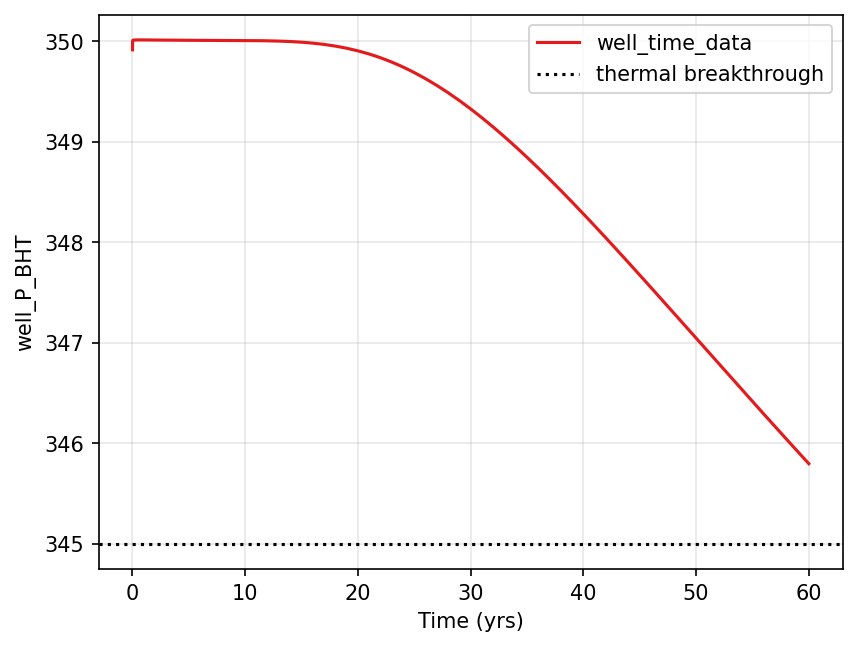

In [12]:
data['Time (yrs)'] = data['time'] / 365.25
fig, ax = plt.subplots(1,1, dpi=150)
sns.lineplot(x='Time (yrs)', y='well_P_BHT', 
             hue='Simulation',  
             style='Simulation',
             data=data, 
             palette='Set1', 
             ax=ax)
ax.axhline(345, linestyle=':', label='thermal breakthrough', color='k')
ax.legend()
ax.grid(alpha=0.3)

In [13]:
# load example simulation data
data = pd.read_excel(flist[0])
data.head(10)

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_P_perf_0_molar_rate_wat,well_P_perf_0_molar_rate_gas,well_I_molar_rate_wat_by_sum_perfs,...,well_P_perf_0_advective_heat_rate_wat,well_P_perf_0_advective_heat_rate_gas,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh
0,0.000100,212.555867,300,184.216438,349.916693,1.950944e+06,0,-1.950387e+06,0,1.950944e+06,...,-5.042393e+08,0,9.733607e+07,0,-5.042393e+08,0,9.689705e+07,0,-5.037994e+08,0
1,0.000220,212.914455,300,182.827238,349.947943,1.951004e+06,0,-1.950415e+06,0,1.951004e+06,...,-5.041564e+08,0,9.697822e+07,0,-5.041564e+08,0,9.689783e+07,0,-5.040455e+08,0
2,0.000364,213.097081,300,182.234568,349.952406,1.951009e+06,0,-1.950407e+06,0,1.951009e+06,...,-5.041158e+08,0,9.691378e+07,0,-5.041158e+08,0,9.689823e+07,0,-5.040782e+08,0
3,0.000537,213.210824,300,181.966411,349.952368,1.951011e+06,0,-1.950403e+06,0,1.951011e+06,...,-5.040973e+08,0,9.690276e+07,0,-5.040973e+08,0,9.689848e+07,0,-5.040762e+08,0
4,0.000744,213.287115,300,181.862019,349.952130,1.951013e+06,0,-1.950401e+06,0,1.951013e+06,...,-5.040902e+08,0,9.690048e+07,0,-5.040902e+08,0,9.689865e+07,0,-5.040736e+08,0
5,0.000993,213.337908,300,181.853931,349.952281,1.951014e+06,0,-1.950401e+06,0,1.951014e+06,...,-5.040897e+08,0,9.689971e+07,0,-5.040897e+08,0,9.689876e+07,0,-5.040748e+08,0
6,0.001292,213.368684,300,181.906700,349.952785,1.951015e+06,0,-1.950402e+06,0,1.951015e+06,...,-5.040934e+08,0,9.689930e+07,0,-5.040934e+08,0,9.689883e+07,0,-5.040792e+08,0
7,0.001650,213.382283,300,181.998683,349.953543,1.951015e+06,0,-1.950404e+06,0,1.951015e+06,...,-5.040999e+08,0,9.689903e+07,0,-5.040999e+08,0,9.689886e+07,0,-5.040860e+08,0
8,0.002080,213.380239,300,182.115753,349.954472,1.951015e+06,0,-1.950406e+06,0,1.951015e+06,...,-5.041082e+08,0,9.689883e+07,0,-5.041082e+08,0,9.689885e+07,0,-5.040943e+08,0
9,0.002596,213.363365,300,182.248431,349.955514,1.951014e+06,0,-1.950409e+06,0,1.951014e+06,...,-5.041176e+08,0,9.689867e+07,0,-5.041176e+08,0,9.689881e+07,0,-5.041036e+08,0


In [14]:
# Check available columns in the data
data.columns.tolist()

['time',
 'well_I_BHP',
 'well_I_BHT',
 'well_P_BHP',
 'well_P_BHT',
 'well_I_perf_0_molar_rate_wat',
 'well_I_perf_0_molar_rate_gas',
 'well_P_perf_0_molar_rate_wat',
 'well_P_perf_0_molar_rate_gas',
 'well_I_molar_rate_wat_by_sum_perfs',
 'well_I_molar_rate_gas_by_sum_perfs',
 'well_P_molar_rate_wat_by_sum_perfs',
 'well_P_molar_rate_gas_by_sum_perfs',
 'well_I_molar_rate_wat_at_wh',
 'well_I_molar_rate_gas_at_wh',
 'well_P_molar_rate_wat_at_wh',
 'well_P_molar_rate_gas_at_wh',
 'well_I_perf_0_mass_rate_wat',
 'well_I_perf_0_mass_rate_gas',
 'well_P_perf_0_mass_rate_wat',
 'well_P_perf_0_mass_rate_gas',
 'well_I_mass_rate_wat_by_sum_perfs',
 'well_I_mass_rate_gas_by_sum_perfs',
 'well_P_mass_rate_wat_by_sum_perfs',
 'well_P_mass_rate_gas_by_sum_perfs',
 'well_I_mass_rate_wat_at_wh',
 'well_I_mass_rate_gas_at_wh',
 'well_P_mass_rate_wat_at_wh',
 'well_P_mass_rate_gas_at_wh',
 'well_I_perf_0_volumetric_rate_wat',
 'well_I_perf_0_volumetric_rate_gas',
 'well_P_perf_0_volumetric_rate_wat

In [15]:
# list the collumn names that should be removed
press_gridcells = data.filter(like='reservoir').columns.tolist()
chem_cols = data.filter(like='Kmol').columns.tolist()

# remove collumns from data
data.drop(columns=press_gridcells + chem_cols, inplace=True)


# add time in years
data['Time (yrs)'] = data['time'] / 365.25

data.columns.tolist()

['time',
 'well_I_BHP',
 'well_I_BHT',
 'well_P_BHP',
 'well_P_BHT',
 'well_I_perf_0_molar_rate_wat',
 'well_I_perf_0_molar_rate_gas',
 'well_P_perf_0_molar_rate_wat',
 'well_P_perf_0_molar_rate_gas',
 'well_I_molar_rate_wat_by_sum_perfs',
 'well_I_molar_rate_gas_by_sum_perfs',
 'well_P_molar_rate_wat_by_sum_perfs',
 'well_P_molar_rate_gas_by_sum_perfs',
 'well_I_molar_rate_wat_at_wh',
 'well_I_molar_rate_gas_at_wh',
 'well_P_molar_rate_wat_at_wh',
 'well_P_molar_rate_gas_at_wh',
 'well_I_perf_0_mass_rate_wat',
 'well_I_perf_0_mass_rate_gas',
 'well_P_perf_0_mass_rate_wat',
 'well_P_perf_0_mass_rate_gas',
 'well_I_mass_rate_wat_by_sum_perfs',
 'well_I_mass_rate_gas_by_sum_perfs',
 'well_P_mass_rate_wat_by_sum_perfs',
 'well_P_mass_rate_gas_by_sum_perfs',
 'well_I_mass_rate_wat_at_wh',
 'well_I_mass_rate_gas_at_wh',
 'well_P_mass_rate_wat_at_wh',
 'well_P_mass_rate_gas_at_wh',
 'well_I_perf_0_volumetric_rate_wat',
 'well_I_perf_0_volumetric_rate_gas',
 'well_P_perf_0_volumetric_rate_wat

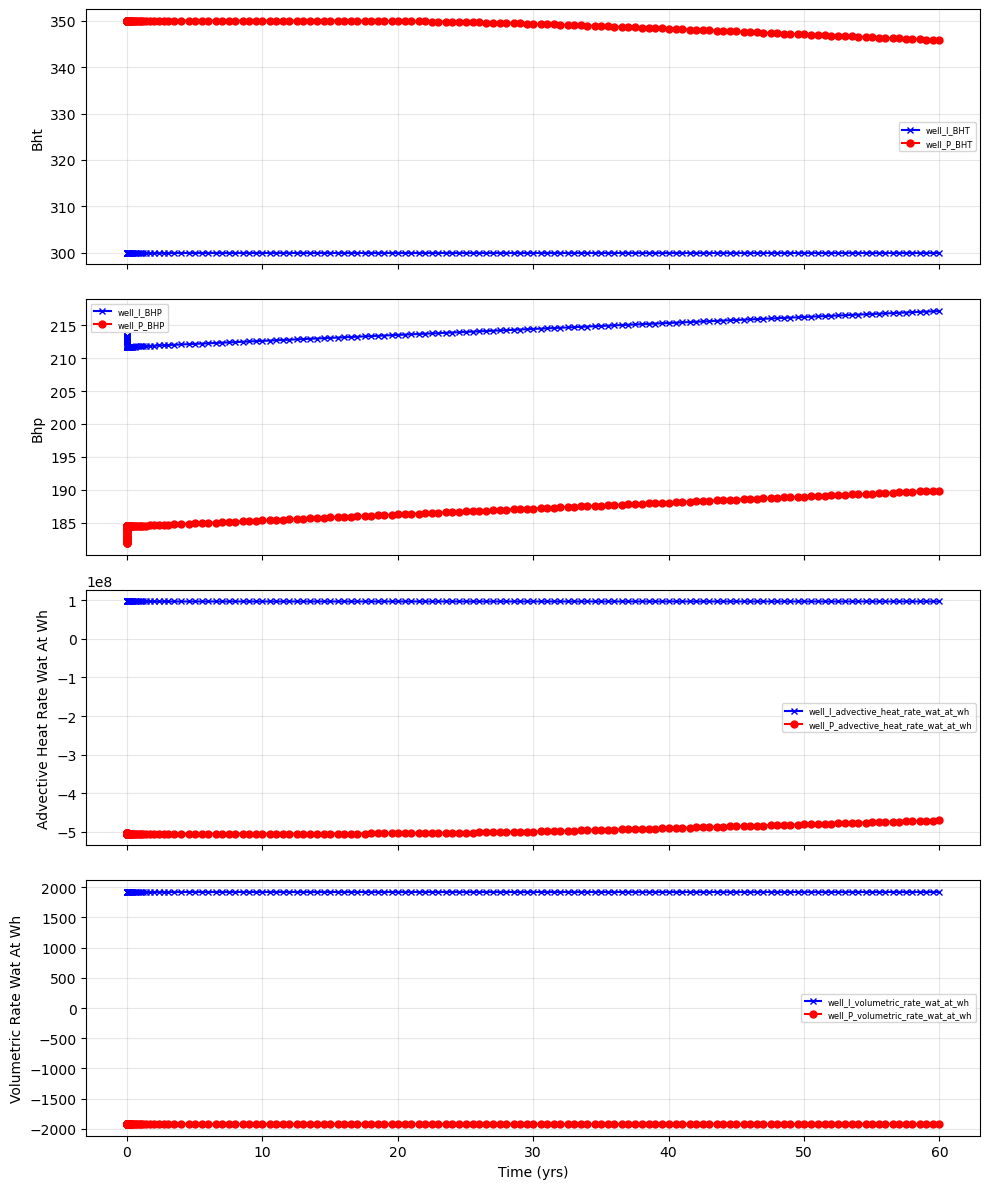

In [16]:
import matplotlib.pyplot as plt

# 1. Create the figure and subplots array (4 plots vertically)
fig, ax_list = plt.subplots(nrows=4, ncols=1, figsize=(10, 12), sharex=True)

# 2. Define keywords
keywords = [
    'BHT', 
    'BHP', 
    'advective_heat_rate_wat_at_wh', 
    'volumetric_rate_wat_at_wh'
]

# 3. Plot loop
for i, key in enumerate(keywords):
    cols = data.filter(like=key).columns.tolist()
    if cols:
        data.plot(
            x='Time (yrs)',
            y=cols,
            ax=ax_list[i],
            linestyle='-',
            style=['x', 'o'],
            markersize=5,
            cmap='bwr'
        )
        ax_list[i].set_ylabel(key.replace('_', ' ').title())
        ax_list[i].legend(fontsize=6)
        ax_list[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()  # Display plot

In [17]:
# assign datetime as index
data['Datetime'] = pd.to_datetime('1/1/2000') + pd.to_timedelta(
                                        data['Time (yrs)'] * pd.Timedelta(('365 days')), unit='s')
data.set_index('Datetime', inplace=True)


# set the new time interval
set_interval = '365D'

# generate the new index on which the data should correspond based on original index range
resample_index = pd.date_range(data.index[0] - pd.Timedelta(set_interval),
                               data.index[-1] + pd.Timedelta(set_interval), 
                               freq=set_interval, normalize=True,
                               inclusive='right')



In [18]:
# create a new index as the union of the old and new index and interpolate on the combined index
# then reindex the dataframe to the new index
tdata = data.reindex(data.index.union(resample_index)).interpolate('index').reindex(resample_index)

# maintain initial values of original dataset in the newly indexed one at the edges
tdata.iloc[0] = data.iloc[0]
tdata.iloc[-1] = data.iloc[-1]

# add the number of periods for further economic assessment
tdata['econ_periods'] = np.arange(len(tdata))

In [19]:
tdata.head()

,time,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_P_perf_0_molar_rate_wat,well_P_perf_0_molar_rate_gas,well_I_molar_rate_wat_by_sum_perfs,...,well_I_advective_heat_rate_wat_by_sum_perfs,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh,Time (yrs),econ_periods
2000-01-01,0.0001,212.555867,300.0,184.216438,349.916693,1.950944e+06,0.0,-1.950387e+06,0.0,1.950944e+06,...,9.733607e+07,0.0,-5.042393e+08,0.0,9.689705e+07,0.0,-5.037994e+08,0.0,2.737851e-07,0
2000-12-31,365.2500,211.820838,300.0,184.504042,350.015394,1.950984e+06,0.0,-1.950453e+06,0.0,1.950984e+06,...,9.689544e+07,0.0,-5.046206e+08,0.0,9.689544e+07,0.0,-5.046059e+08,0.0,1.000000e+00,1
2001-12-31,730.5000,211.911666,300.0,184.594876,350.014127,1.950986e+06,0.0,-1.950454e+06,0.0,1.950986e+06,...,9.689563e+07,0.0,-5.046108e+08,0.0,9.689564e+07,0.0,-5.045961e+08,0.0,2.000000e+00,2
2002-12-31,1095.7500,212.002494,300.0,184.685710,350.013046,1.950988e+06,0.0,-1.950456e+06,0.0,1.950988e+06,...,9.689583e+07,0.0,-5.046026e+08,0.0,9.689584e+07,0.0,-5.045879e+08,0.0,3.000000e+00,3
2003-12-31,1461.0000,212.093322,300.0,184.776544,350.012223,1.950990e+06,0.0,-1.950458e+06,0.0,1.950990e+06,...,9.689603e+07,0.0,-5.045964e+08,0.0,9.689604e+07,0.0,-5.045817e+08,0.0,4.000000e+00,4


In [20]:
# compute the deltahours for economic and energy assessments
tdata['Deltahours'] = tdata.index.to_series().diff(1) / pd.Timedelta('1 hour')

# verify that we only have one delta
tdata['Deltahours'].unique()


array([  nan, 8760.])

In [21]:
# recompute time columns based on index
tdata['Time (yrs)'] = pd.to_timedelta(tdata.index - tdata.index[0]).total_seconds() / (365 * 24 * 60 * 60)

# reset index to time delta
tdata.set_index(pd.to_timedelta(tdata['Time (yrs)'] * pd.Timedelta(('365 days')), unit='s'), inplace=True)
tdata.drop(columns='time', inplace=True)

In [22]:
tdata.head()

,well_I_BHP,well_I_BHT,well_P_BHP,well_P_BHT,well_I_perf_0_molar_rate_wat,well_I_perf_0_molar_rate_gas,well_P_perf_0_molar_rate_wat,well_P_perf_0_molar_rate_gas,well_I_molar_rate_wat_by_sum_perfs,well_I_molar_rate_gas_by_sum_perfs,...,well_I_advective_heat_rate_gas_by_sum_perfs,well_P_advective_heat_rate_wat_by_sum_perfs,well_P_advective_heat_rate_gas_by_sum_perfs,well_I_advective_heat_rate_wat_at_wh,well_I_advective_heat_rate_gas_at_wh,well_P_advective_heat_rate_wat_at_wh,well_P_advective_heat_rate_gas_at_wh,Time (yrs),econ_periods,Deltahours
Time (yrs),,,,,,,,,,,,,,,,,,,,,
0 days,212.555867,300.0,184.216438,349.916693,1.950944e+06,0.0,-1.950387e+06,0.0,1.950944e+06,0.0,...,0.0,-5.042393e+08,0.0,9.689705e+07,0.0,-5.037994e+08,0.0,0.0,0,NaN
365 days,211.820838,300.0,184.504042,350.015394,1.950984e+06,0.0,-1.950453e+06,0.0,1.950984e+06,0.0,...,0.0,-5.046206e+08,0.0,9.689544e+07,0.0,-5.046059e+08,0.0,1.0,1,8760.0
730 days,211.911666,300.0,184.594876,350.014127,1.950986e+06,0.0,-1.950454e+06,0.0,1.950986e+06,0.0,...,0.0,-5.046108e+08,0.0,9.689564e+07,0.0,-5.045961e+08,0.0,2.0,2,8760.0
1095 days,212.002494,300.0,184.685710,350.013046,1.950988e+06,0.0,-1.950456e+06,0.0,1.950988e+06,0.0,...,0.0,-5.046026e+08,0.0,9.689584e+07,0.0,-5.045879e+08,0.0,3.0,3,8760.0
1460 days,212.093322,300.0,184.776544,350.012223,1.950990e+06,0.0,-1.950458e+06,0.0,1.950990e+06,0.0,...,0.0,-5.045964e+08,0.0,9.689604e+07,0.0,-5.045817e+08,0.0,4.0,4,8760.0


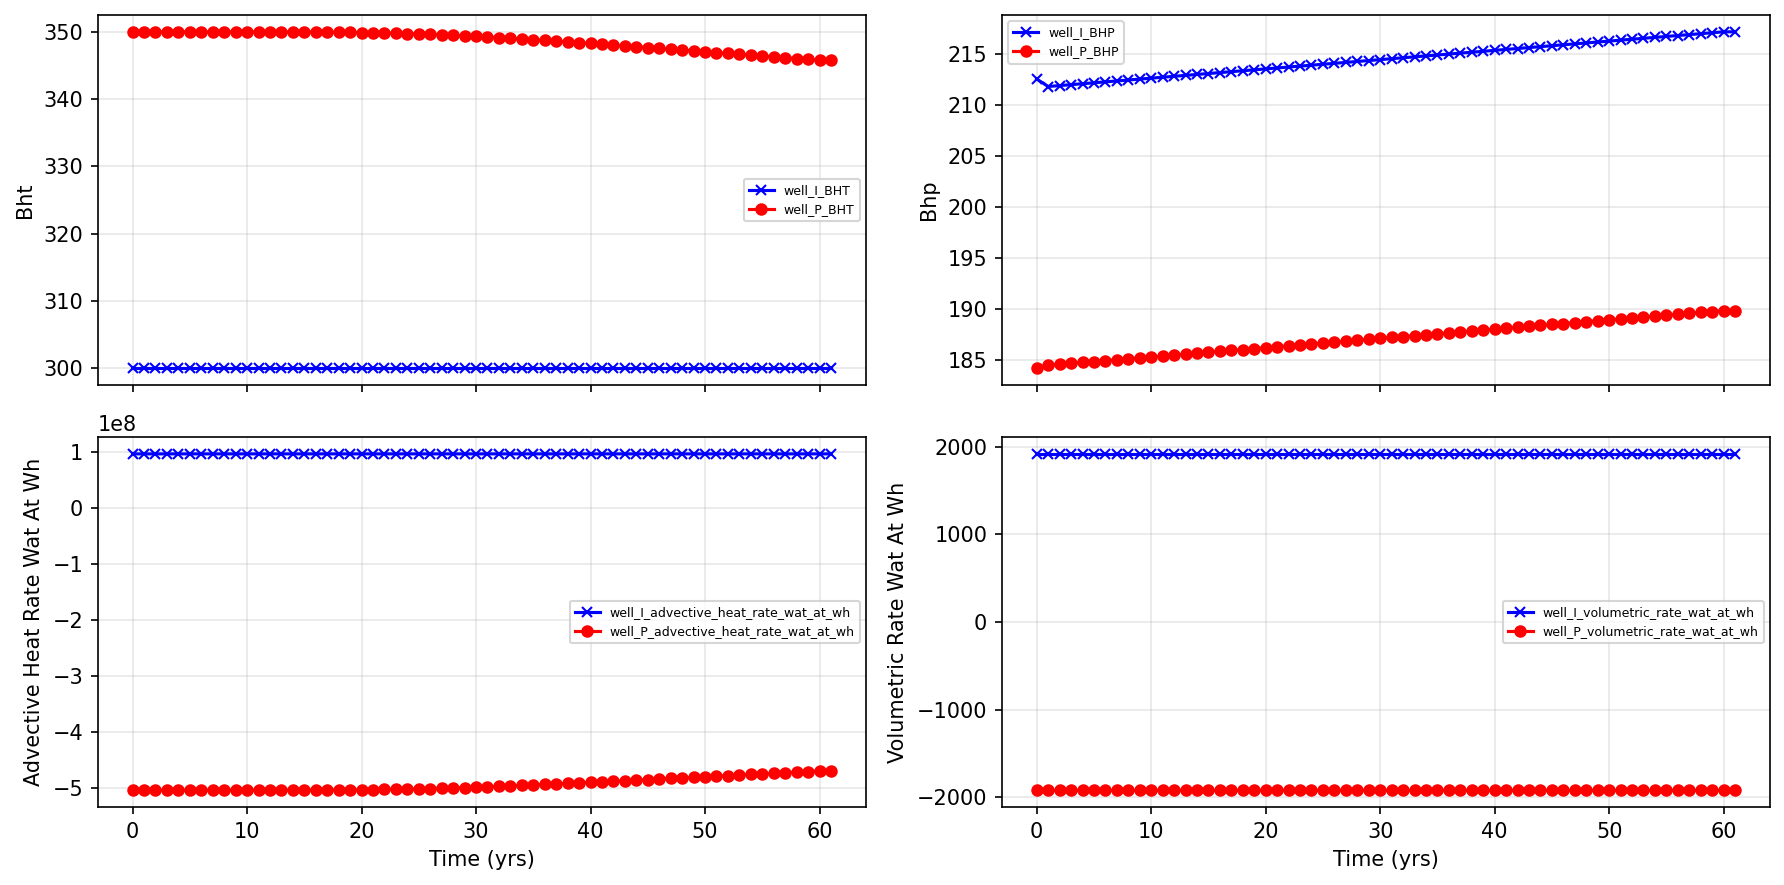

In [23]:
import matplotlib.pyplot as plt

# 1. Define the 2x2 plot layout
fig, ax = plt.subplots(2, 2, figsize=(12, 6), dpi=150, sharex=True)
ax_list = fig.axes

# 2. Define keywords matching your new column names
keywords = [
    'BHT',                          # Temperature (Injector & Producer)
    'BHP',                          # Bottom Hole Pressure
    'advective_heat_rate_wat_at_wh',# Heat rate / Energy at wellhead
    'volumetric_rate_wat_at_wh'     # Water rate at wellhead
]

# 3. Loop and plot for both wells using tdata
for i, key in enumerate(keywords):
    # Filter columns directly from tdata
    cols = tdata.filter(like=key).columns.tolist()
    
    if cols:
        tdata.plot(
            x='Time (yrs)',                # or 'Time (yrs)' depending on your tdata index/column
            y=cols,
            ax=ax_list[i],
            linestyle='-',
            style=['x', 'o'], 
            markersize=5,
            cmap='bwr'
        )
        ax_list[i].set_ylabel(key.replace('_', ' ').title())
        ax_list[i].legend(fontsize=6)
        ax_list[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()

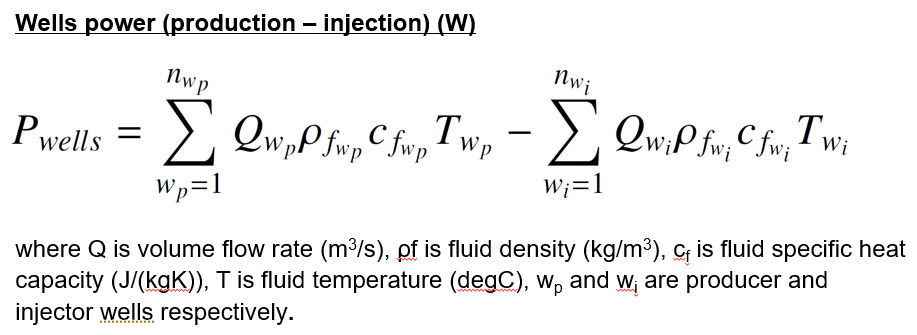

In [24]:
kJ_day_MW = 1/3.6e6/24
m3_day_m3_sec = 1 / (24 * 60 * 60)

# compute fluid properties for each well
tdata['well_PRD_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(tdata['PRD : BHP (bar)']*0.1 * 1e6, tdata['PRD : temperature (K)'])]
tdata['well_PRD_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(tdata['PRD : BHP (bar)']*0.1 * 1e6, tdata['PRD : temperature (K)'])]

tdata['well_INJ_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(tdata['INJ : BHP (bar)']*0.1 * 1e6, tdata['INJ : temperature (K)'])]
tdata['well_INJ_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(tdata['INJ : BHP (bar)']*0.1 * 1e6, tdata['INJ : temperature (K)'])]

# compute power for each well
tdata['well_PRD_power'] = 1e-6 * tdata['PRD : water rate (m3/day)']* m3_day_m3_sec * \
                             tdata['well_PRD_rho'] * tdata['well_PRD_cp'] * tdata['PRD : temperature (K)']

tdata['well_INJ_power'] = 1e-6 * tdata['INJ : water rate (m3/day)']* m3_day_m3_sec * \
                             tdata['well_INJ_rho'] * tdata['well_INJ_cp'] * tdata['INJ : temperature (K)']

# compute system power
tdata['system_power (MW)'] = abs(tdata['well_PRD_power']) - abs(tdata['well_INJ_power'])


# compute produced energy
tdata['Produced Energy (MWh)'] = tdata['system_power (MW)'] * tdata['Deltahours']

tdata.plot(x='Time (yrs)', y=['system_power (MW)'])

KeyError: 'PRD : BHP (bar)'

Time (yrs)
0 days                 NaN
365 days      35557.544870
730 days      35556.931177
1095 days     35556.443997
1460 days     35556.130896
1825 days     35555.936123
2190 days     35555.830991
2555 days     35555.789027
2920 days     35555.774310
3285 days     35555.728290
3650 days     35555.555029
4015 days     35555.107284
4380 days     35554.176844
4745 days     35552.491811
5110 days     35549.721719
5475 days     35545.489931
5840 days     35539.391389
6205 days     35531.013049
6570 days     35519.954437
6935 days     35505.846130
7300 days     35488.364675
7665 days     35467.243227
8030 days     35442.277763
8395 days     35413.329232
8760 days     35380.322282
9125 days     35343.241318
9490 days     35302.124697
9855 days     35257.057755
10220 days    35208.165314
10585 days    35155.604127
10950 days    35099.555650
11315 days    35040.219354
11680 days    34977.806782
12045 days    34912.536365
12410 days    34844.629052
12775 days    34774.304724
13140 days    347

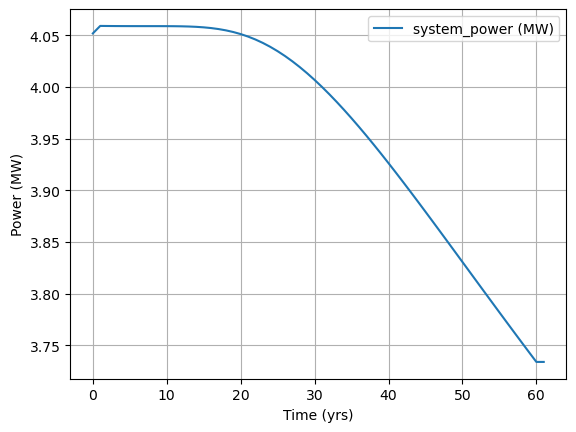

In [25]:
import sys

import numpy as np

# Unit conversion factors
kJ_day_MW = 1 / 3.6e6 / 24
m3_day_m3_sec = 1 / (24 * 60 * 60)

# Convert temperatures from Celsius to Kelvin if needed (assuming BHT is in °C)
# If your BHT is already in Kelvin, omit the + 273.15
t_inj_k = tdata['well_I_BHT'] 
t_prd_k = tdata['well_P_BHT'] 

# Pressure conversion: bar -> Pa (1 bar = 1e5 Pa)
p_inj_pa = tdata['well_I_BHP'] * 1e5
p_prd_pa = tdata['well_P_BHP'] * 1e5

# 1. Compute fluid properties for each well (I = Injector, P = Producer)
tdata['well_PRD_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_prd_pa, t_prd_k)]
tdata['well_PRD_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_prd_pa, t_prd_k)]

tdata['well_INJ_rho'] = [PropsSI('D', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_inj_pa, t_inj_k)]
tdata['well_INJ_cp']  = [PropsSI('C', 'P', P, 'T', T, 'IF97::Water') for P, T in zip(p_inj_pa, t_inj_k)]

# 2. Compute thermal power for each well (using volumetric rate at wellhead)
# Note: 'well_P_volumetric_rate_wat_at_wh' is used as the updated equivalent for water rate
tdata['well_PRD_power'] = 1e-6 * tdata['well_P_volumetric_rate_wat_at_wh'] * m3_day_m3_sec * \
                             tdata['well_PRD_rho'] * tdata['well_PRD_cp'] * t_prd_k

tdata['well_INJ_power'] = 1e-6 * tdata['well_I_volumetric_rate_wat_at_wh'] * m3_day_m3_sec * \
                             tdata['well_INJ_rho'] * tdata['well_INJ_cp'] * t_inj_k

# 3. Compute net system thermal power (MW)
tdata['system_power (MW)'] = np.abs(tdata['well_PRD_power']) - np.abs(tdata['well_INJ_power'])

# 4. Compute cumulative produced energy (MWh)
tdata['Produced Energy (MWh)'] = tdata['system_power (MW)'] * tdata['Deltahours'] 

# 5. Plot net thermal power against time
tdata.plot(x='Time (yrs)', y=['system_power (MW)'], ylabel='Power (MW)', grid=True)

import pandas as pd
#pd.set_option('display.max_rows', None)  # Set threshold to maximum size to print all values
#print(tdata['system_power (MW)'][0:60])

import pandas as pd
pd.set_option('display.max_rows', None)  # Set threshold to maximum size to print all values
print(tdata['Produced Energy (MWh)'][0:60])

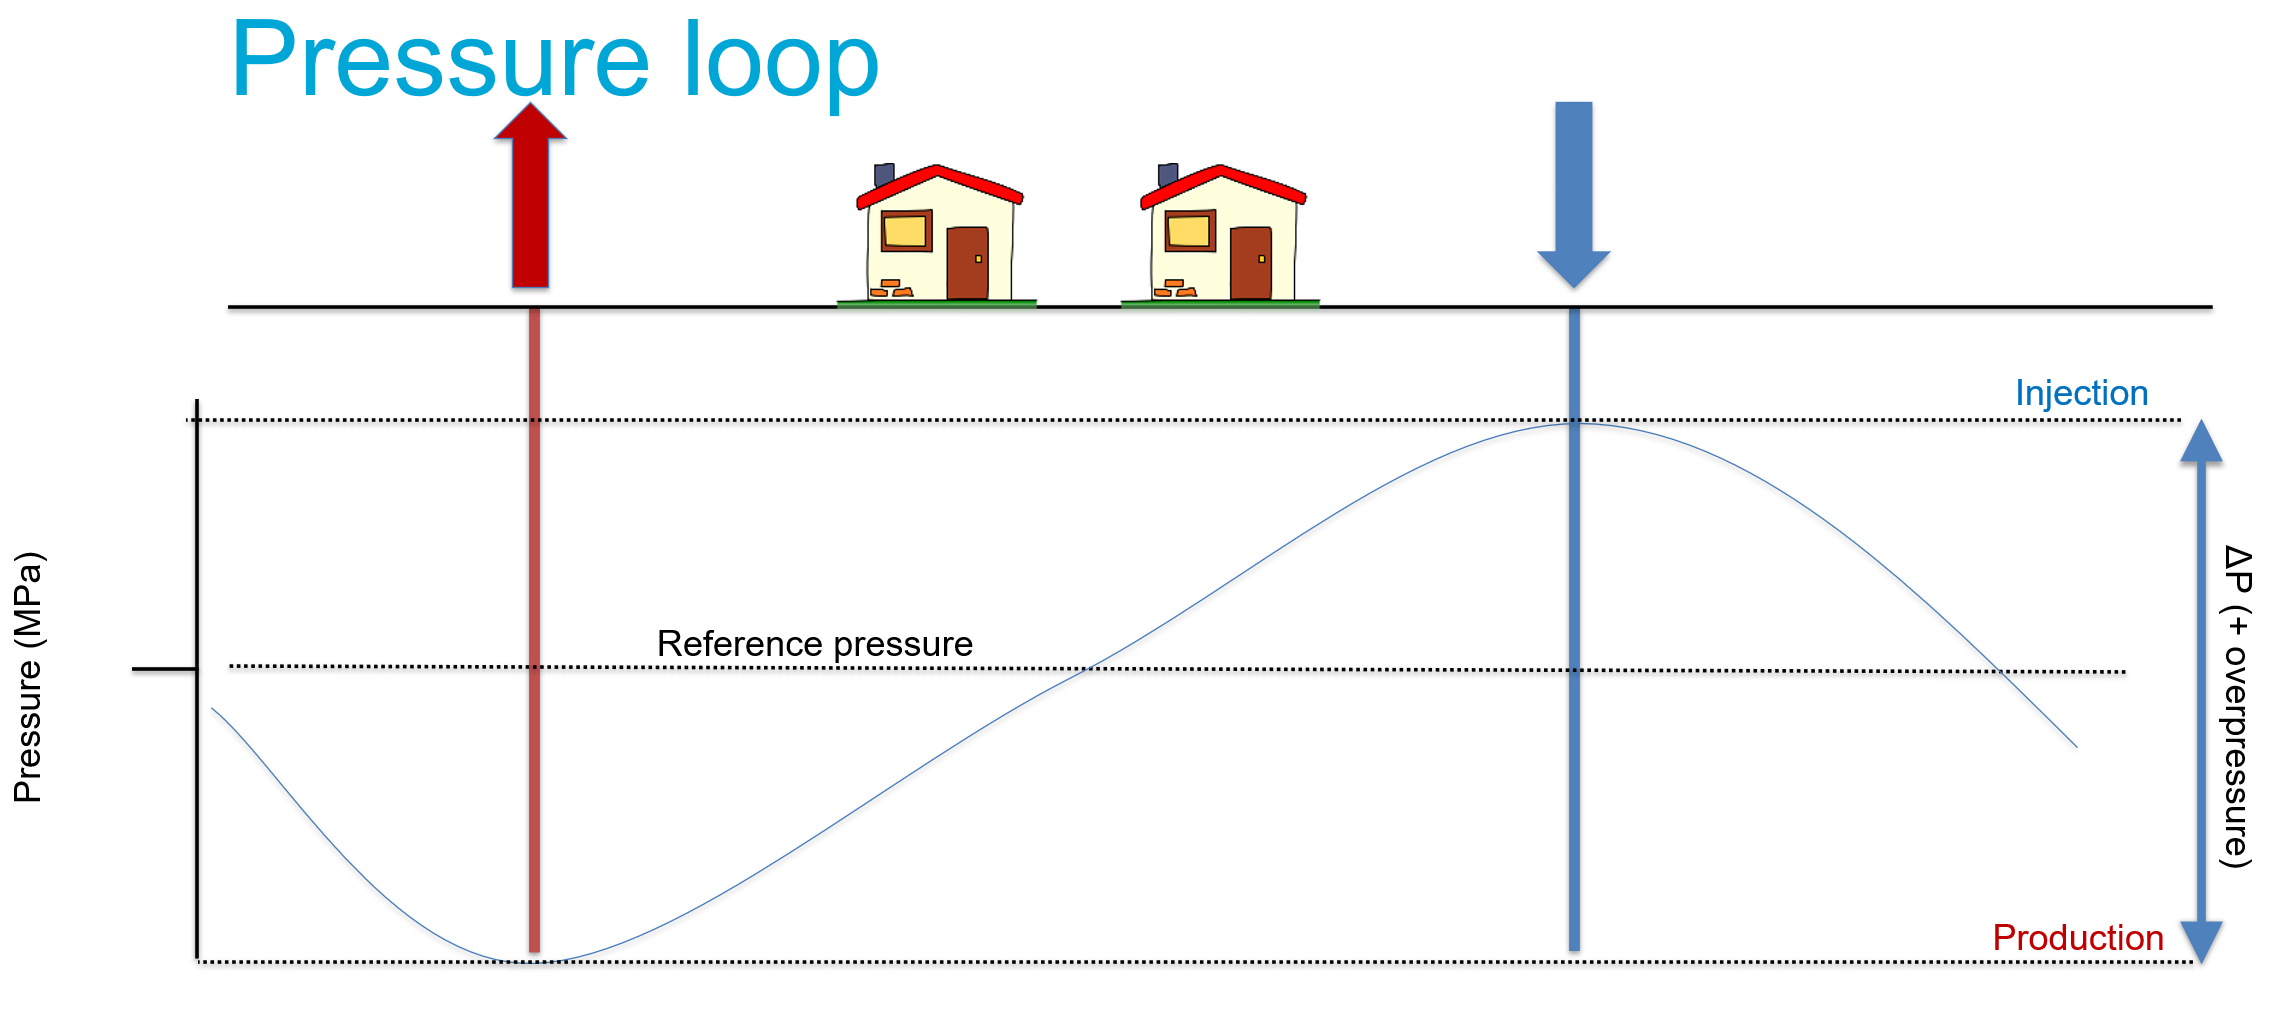

In [ ]:
# compute the pressure drop
tdata['Pump dp (MPa)'] = abs(tdata['well_P_BHP'] * 0.1) - abs(tdata['well_I_BHP']*0.1)

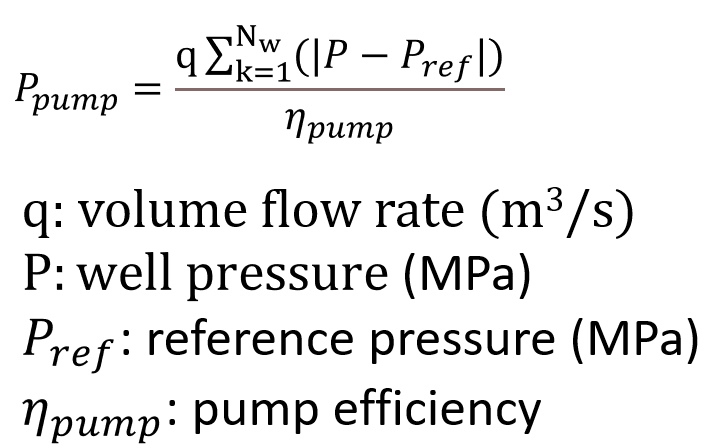

In [ ]:
m3_day_m3_sec = 1 / (24 * 60 * 60)
pump_efficiency = 0.5

# compute the pumping power
tdata['Pump power (MW)'] = abs(tdata['Pump dp (MPa)']) * \
                             abs(tdata['well_I_volumetric_rate_wat_at_wh']) * m3_day_m3_sec / pump_efficiency

# compute the pumping costs
electricity_price = 120 # euro/MWh
tdata['OpEx_pump (\u20ac)'] = tdata['Pump power (MW)'] * tdata['Deltahours'] * electricity_price

In [ ]:
# assign the CapEx for drilling the wells
tdata['CapEx (\u20ac)'] = 0
tdata.loc[tdata.index == tdata.index[0], 'CapEx (\u20ac)'] = 2 * 1.5* 4113000

periodic_OpEx_rate = 0.03
# calculate variable OpEx costs
tdata['OpEx (\u20ac)'] = tdata['CapEx (\u20ac)'].cumsum() * periodic_OpEx_rate



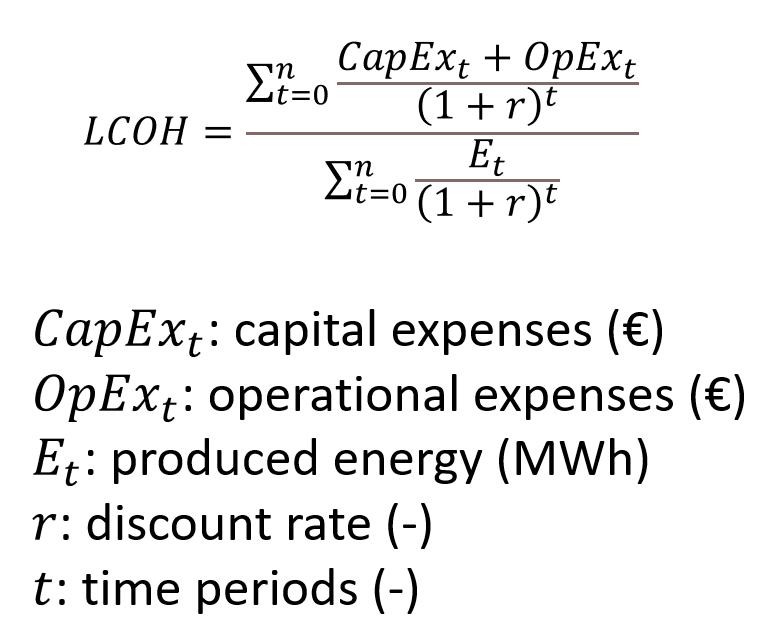

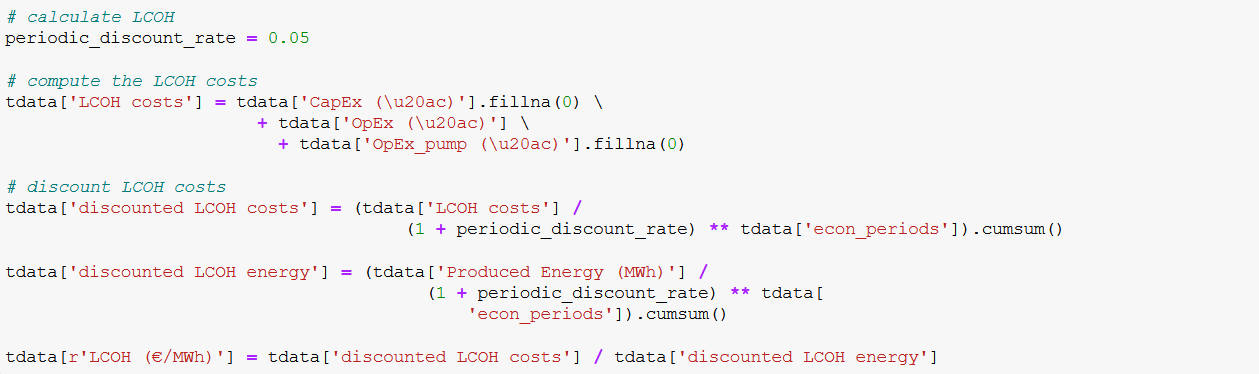

In [ ]:
# calculate LCOH
periodic_discount_rate = 0.05

# compute the LCOH costs
tdata['LCOH costs'] = tdata['CapEx (\u20ac)'].fillna(0) \
                        + tdata['OpEx (\u20ac)'] \
                          + tdata['OpEx_pump (\u20ac)'].fillna(0)

# discount LCOH costs
tdata['discounted LCOH costs'] = (tdata['LCOH costs'] /
                                      (1 + periodic_discount_rate) ** tdata['econ_periods']).cumsum()

tdata['discounted LCOH energy'] = (tdata['Produced Energy (MWh)'] /
                                        (1 + periodic_discount_rate) ** tdata[
                                            'econ_periods']).cumsum()

tdata[r'LCOH (€/MWh)'] = tdata['discounted LCOH costs'] / tdata['discounted LCOH energy']



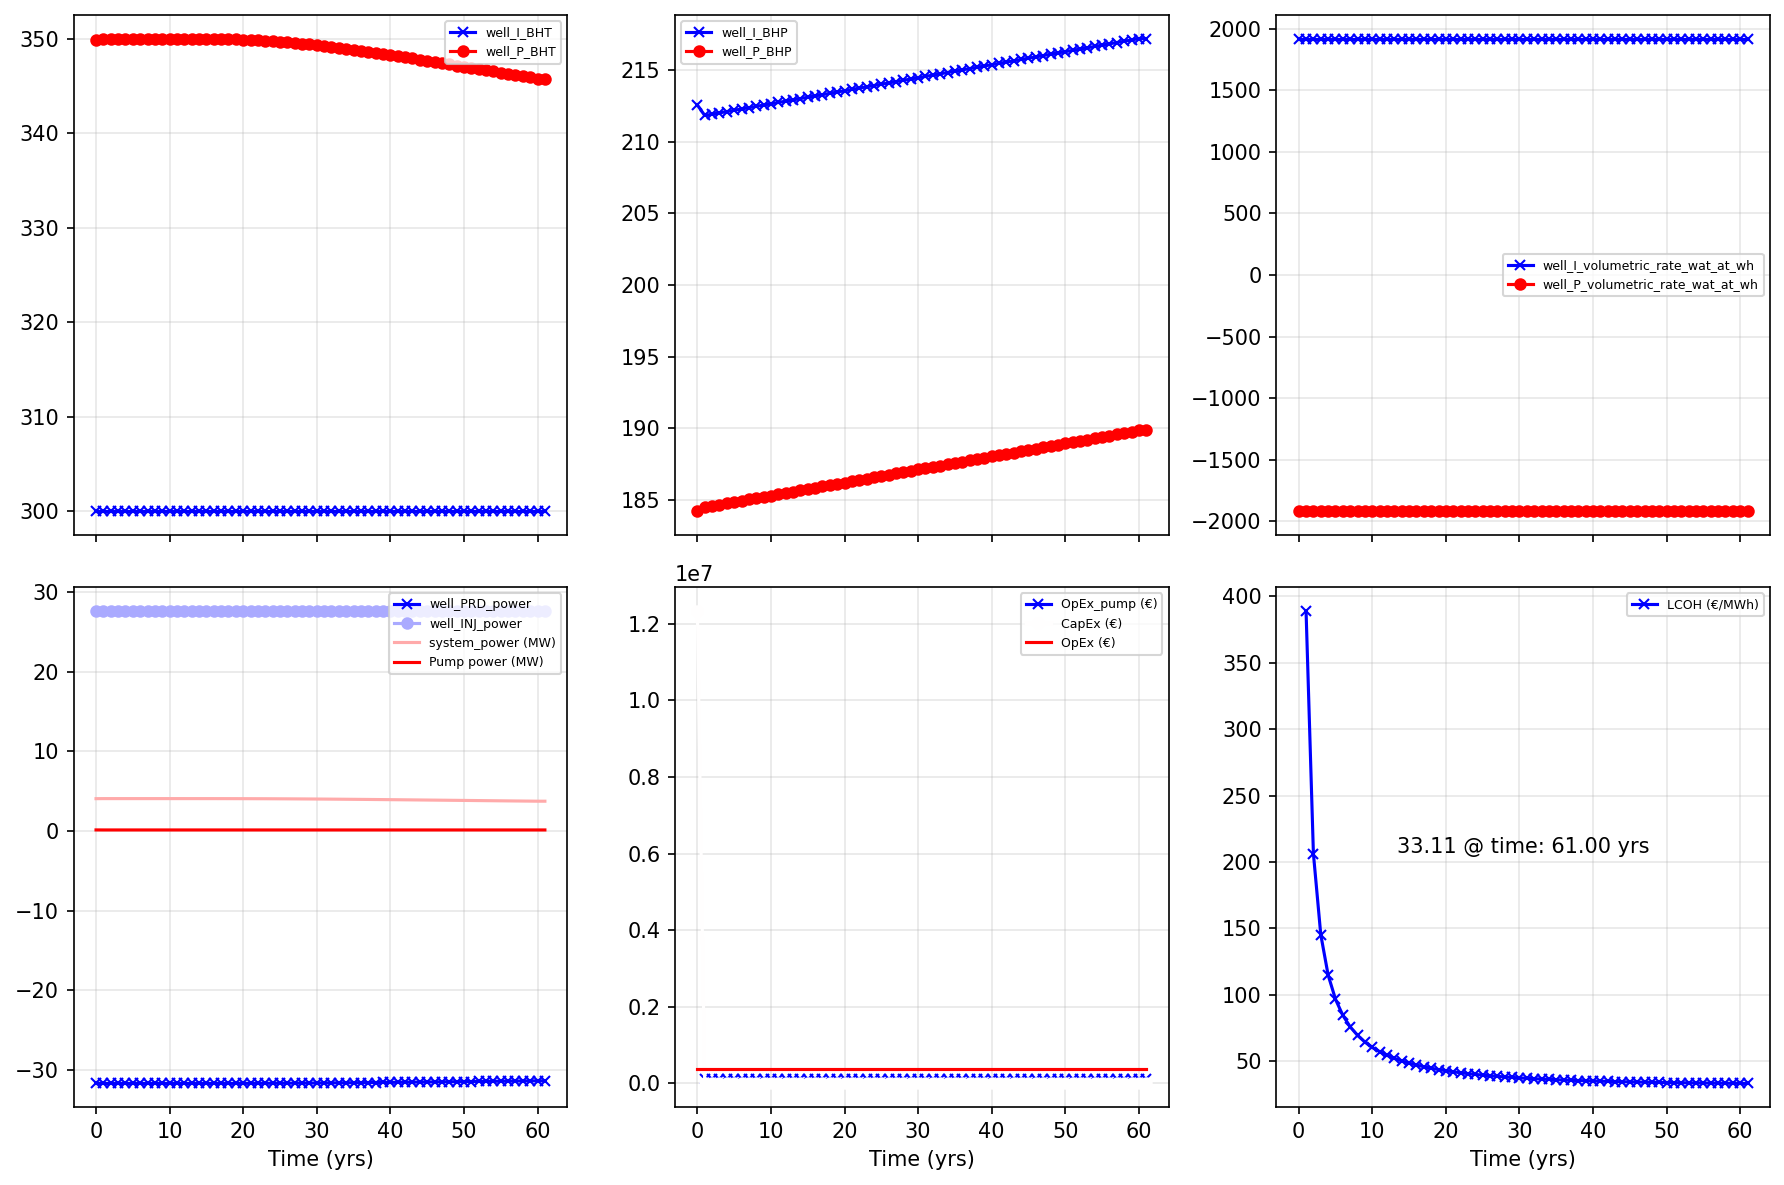

In [ ]:
import matplotlib.pyplot as plt

# 1. Define a 2x3 subplot grid
fig, ax = plt.subplots(2, 3, figsize=(12, 8), dpi=150, sharex=True)
ax_list = fig.axes

# 2. Define keywords: updated first 3 to match new headers; kept power, Ex, and LCOH as-is
keywords = [
    'BHT',                           # Temperature (Injector & Producer)
    'BHP',                           # Bottom Hole Pressure
    'volumetric_rate_wat_at_wh',     # Water rate at wellhead
    'power',                         # Kept as-is
    'Ex',                            # Kept as-is
    'LCOH (€/MWh)'                   # Kept as-is
]

# 3. Plot each keyword
for i, key in enumerate(keywords):
    # Filter matching columns from tdata
    cols = tdata.filter(like=key).columns.tolist()
    
    if cols:
        tdata.plot(
            x='Time (yrs)',                # Updated to 'time' (use 'Time (yrs)' if preferred)
            y=cols,
            ax=ax_list[i],
            linestyle='-',
            style=['x', 'o'],
            markersize=5,
            cmap='bwr'
        )
        ax_list[i].legend(fontsize=6)
        ax_list[i].grid(alpha=0.3)
        
    # LCOH annotation handling
    if key == 'LCOH (€/MWh)' and 'LCOH (€/MWh)' in tdata.columns:
        ax_list[i].annotate(
            '%0.2f @ time: %.2f yrs' % (tdata[key].iloc[-1], tdata['Time (yrs)'].iloc[-1]),
            xy=(0.5, 0.5), va='center', ha='center',
            xycoords='axes fraction'
        )

plt.tight_layout()
plt.show()

TypeError: no numeric data to plot

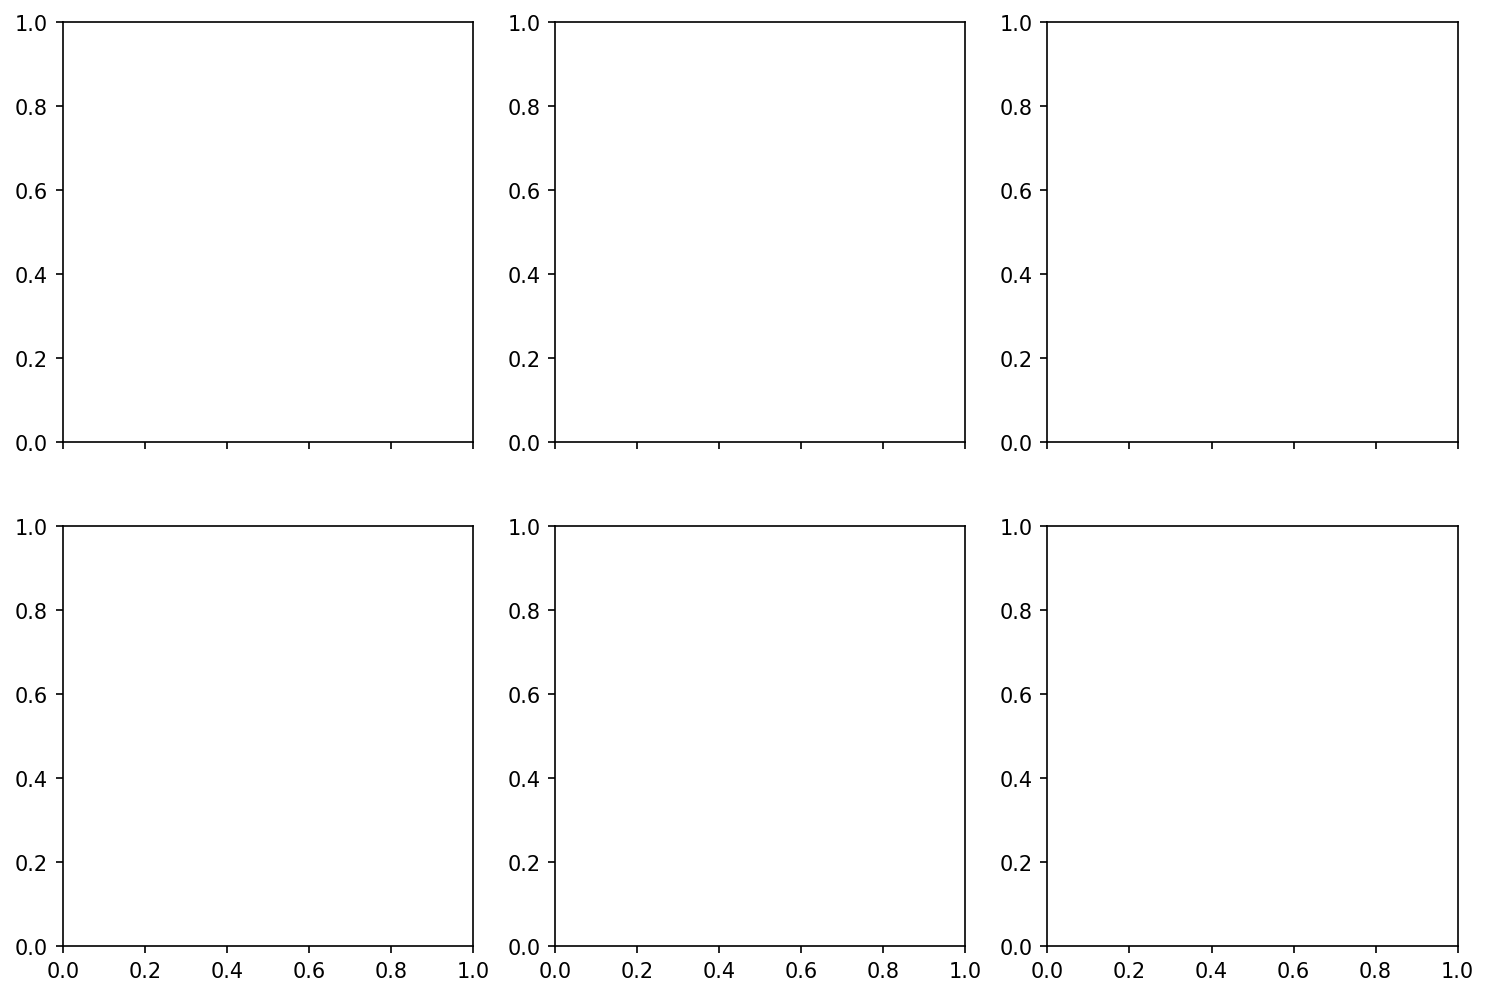

In [ ]:
# do our final plot with the overview
# define a plot
fig, ax = plt.subplots(2,3, figsize=(12,8), dpi=150, sharex=True)
# get plot axes
ax_list = fig.axes

# plot a few keywords in pairs for both wells
for i, key in enumerate(['temperature', 'BHP','water rate (m3/day)',
                         'power', 'Ex','LCOH (€/MWh)']):
    tdata.plot(x='Time (yrs)',
              y=tdata.filter(like=key).columns.tolist(),
              ax=ax_list[i],
              linestyle='-',
              style=['x', 'o'], 
              markersize=5,
              cmap='bwr')
    ax_list[i].legend(fontsize=6)
    ax_list[i].grid(alpha=0.3)
    if key == 'LCOH (€/MWh)':
        ax_list[i].annotate('%0.2f @ time: %.2f yrs' % (tdata[key].iloc[-1], tdata['Time (yrs)'].iloc[-1]),
                            xy=(0.5, 0.5), va='center', ha='center',
                            xycoords=('axes fraction'))

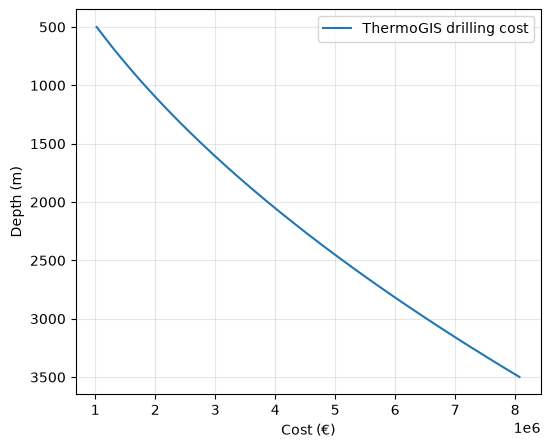

In [ ]:
def drillingcostnl(depth):
    """
    Calculate the cost of drilling as a function of depth
    Reference source:
        https://www.thermogis.nl/en/economic-model

    :param depth: float
        measured depth along hole in meters

    :return: float
        costs in euros
    """
    drilling_cost_nl = 375000 + 1150 * depth + 0.3 * depth ** 2
    return(drilling_cost_nl)

depth = np.arange(500, 3500, 1)
costs = drillingcostnl(depth)

fig, ax = plt.subplots(figsize=(6,5))
ax.plot(costs, depth, label='ThermoGIS drilling cost')
ax.set_xlabel('Cost (€)')
ax.set_ylabel('Depth (m)')
ax.grid(alpha=0.3)
ax.legend()
ax.invert_yaxis()

#### Importing the "new" DARTS output files, a working example ####

In [ ]:
tdata = pd.read_excel(flist[-1])

In [ ]:
tdata

,Unnamed: 0,time,well_PRD_BHP,well_PRD_BHT,well_INJ_BHP,well_INJ_BHT,well_PRD_perf_0_molar_rate_water,well_PRD_perf_0_molar_rate_steam,well_PRD_perf_1_molar_rate_water,well_PRD_perf_1_molar_rate_steam,...,well_INJ_perf_9_advective_heat_rate_water,well_INJ_perf_9_advective_heat_rate_steam,well_PRD_advective_heat_rate_water_by_sum_perfs,well_PRD_advective_heat_rate_steam_by_sum_perfs,well_INJ_advective_heat_rate_water_by_sum_perfs,well_INJ_advective_heat_rate_steam_by_sum_perfs,well_PRD_advective_heat_rate_water_at_wh,well_PRD_advective_heat_rate_steam_at_wh,well_INJ_advective_heat_rate_water_at_wh,well_INJ_advective_heat_rate_steam_at_wh
0,0,0.01,143.935571,355.404470,300.0,300.000115,-1125.629864,0,-1144.555928,0,...,2.666898e+07,0,-1.028711e+10,0,1.291238e+10,0,-9.413699e+09,0,1.350920e+10,0
1,1,0.03,135.641596,355.376507,300.0,300.000115,-1273.803883,0,-1285.813699,0,...,2.654857e+07,0,-1.027688e+10,0,1.192567e+10,0,-9.404206e+09,0,1.252225e+10,0
2,2,0.07,129.912396,355.358645,300.0,300.000115,-1355.981723,0,-1352.656691,0,...,2.632076e+07,0,-1.026974e+10,0,1.131608e+10,0,-9.397598e+09,0,1.191270e+10,0
3,3,0.15,125.480881,355.345887,300.0,300.000115,-1386.263736,0,-1356.479707,0,...,2.591484e+07,0,-1.026416e+10,0,1.089741e+10,0,-9.392423e+09,0,1.149411e+10,0
4,4,0.31,121.751312,355.339066,300.0,300.000115,-1365.716725,0,-1301.892534,0,...,2.525724e+07,0,-1.025933e+10,0,1.058894e+10,0,-9.387896e+09,0,1.118574e+10,0
5,5,0.63,118.685507,355.338103,300.0,300.000115,-1295.404130,0,-1204.850801,0,...,2.433559e+07,0,-1.025511e+10,0,1.037779e+10,0,-9.383961e+09,0,1.097477e+10,0
6,6,1.27,116.384746,355.348420,300.0,300.000115,-1191.965247,0,-1099.225199,0,...,2.325709e+07,0,-1.025146e+10,0,1.024733e+10,0,-9.380509e+09,0,1.084463e+10,0
7,7,2.55,114.848448,355.376955,300.0,300.000115,-1082.186215,0,-1016.284083,0,...,2.219509e+07,0,-1.024808e+10,0,1.015410e+10,0,-9.377233e+09,0,1.075198e+10,0
8,8,5.11,113.925997,355.431016,300.0,300.000115,-990.462345,0,-963.955280,0,...,2.127282e+07,0,-1.024446e+10,0,1.004119e+10,0,-9.373611e+09,0,1.064003e+10,0
9,9,10.23,113.385710,355.512922,300.0,300.000115,-933.585992,0,-936.609876,0,...,2.058156e+07,0,-1.024019e+10,0,9.842389e+09,0,-9.369250e+09,0,1.044260e+10,0


In [ ]:
tdata.columns.tolist()

['Unnamed: 0',
 'time',
 'well_PRD_BHP',
 'well_PRD_BHT',
 'well_INJ_BHP',
 'well_INJ_BHT',
 'well_PRD_perf_0_molar_rate_water',
 'well_PRD_perf_0_molar_rate_steam',
 'well_PRD_perf_1_molar_rate_water',
 'well_PRD_perf_1_molar_rate_steam',
 'well_PRD_perf_2_molar_rate_water',
 'well_PRD_perf_2_molar_rate_steam',
 'well_PRD_perf_3_molar_rate_water',
 'well_PRD_perf_3_molar_rate_steam',
 'well_PRD_perf_4_molar_rate_water',
 'well_PRD_perf_4_molar_rate_steam',
 'well_PRD_perf_5_molar_rate_water',
 'well_PRD_perf_5_molar_rate_steam',
 'well_PRD_perf_6_molar_rate_water',
 'well_PRD_perf_6_molar_rate_steam',
 'well_PRD_perf_7_molar_rate_water',
 'well_PRD_perf_7_molar_rate_steam',
 'well_PRD_perf_8_molar_rate_water',
 'well_PRD_perf_8_molar_rate_steam',
 'well_PRD_perf_9_molar_rate_water',
 'well_PRD_perf_9_molar_rate_steam',
 'well_INJ_perf_0_molar_rate_water',
 'well_INJ_perf_0_molar_rate_steam',
 'well_INJ_perf_1_molar_rate_water',
 'well_INJ_perf_1_molar_rate_steam',
 'well_INJ_perf_2_mo

In [ ]:
# list the collumn names that should be removed
perf_gridcells = tdata.filter(like='perf').columns.tolist()
molar_gridcells = tdata.filter(like='molar').columns.tolist()

# remove collumns from data
tdata.drop(columns=perf_gridcells + molar_gridcells, inplace=True)

tdata.columns.tolist()

['Unnamed: 0',
 'time',
 'well_PRD_BHP',
 'well_PRD_BHT',
 'well_INJ_BHP',
 'well_INJ_BHT',
 'well_PRD_mass_rate_water_at_wh',
 'well_PRD_mass_rate_steam_at_wh',
 'well_INJ_mass_rate_water_at_wh',
 'well_INJ_mass_rate_steam_at_wh',
 'well_PRD_volumetric_rate_water_at_wh',
 'well_PRD_volumetric_rate_steam_at_wh',
 'well_INJ_volumetric_rate_water_at_wh',
 'well_INJ_volumetric_rate_steam_at_wh',
 'well_PRD_advective_heat_rate_water_at_wh',
 'well_PRD_advective_heat_rate_steam_at_wh',
 'well_INJ_advective_heat_rate_water_at_wh',
 'well_INJ_advective_heat_rate_steam_at_wh']

<Axes: xlabel='time'>

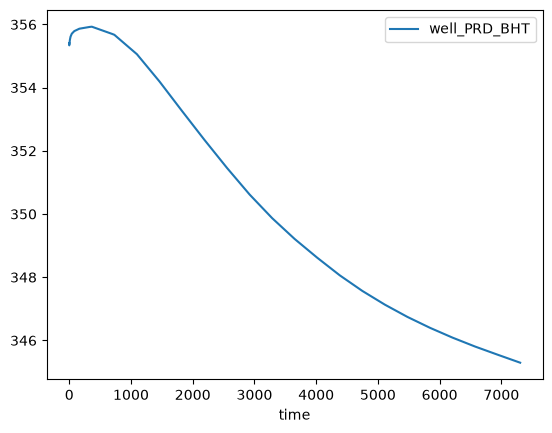

In [ ]:
tdata.plot(x='time', y=['well_PRD_BHT'])

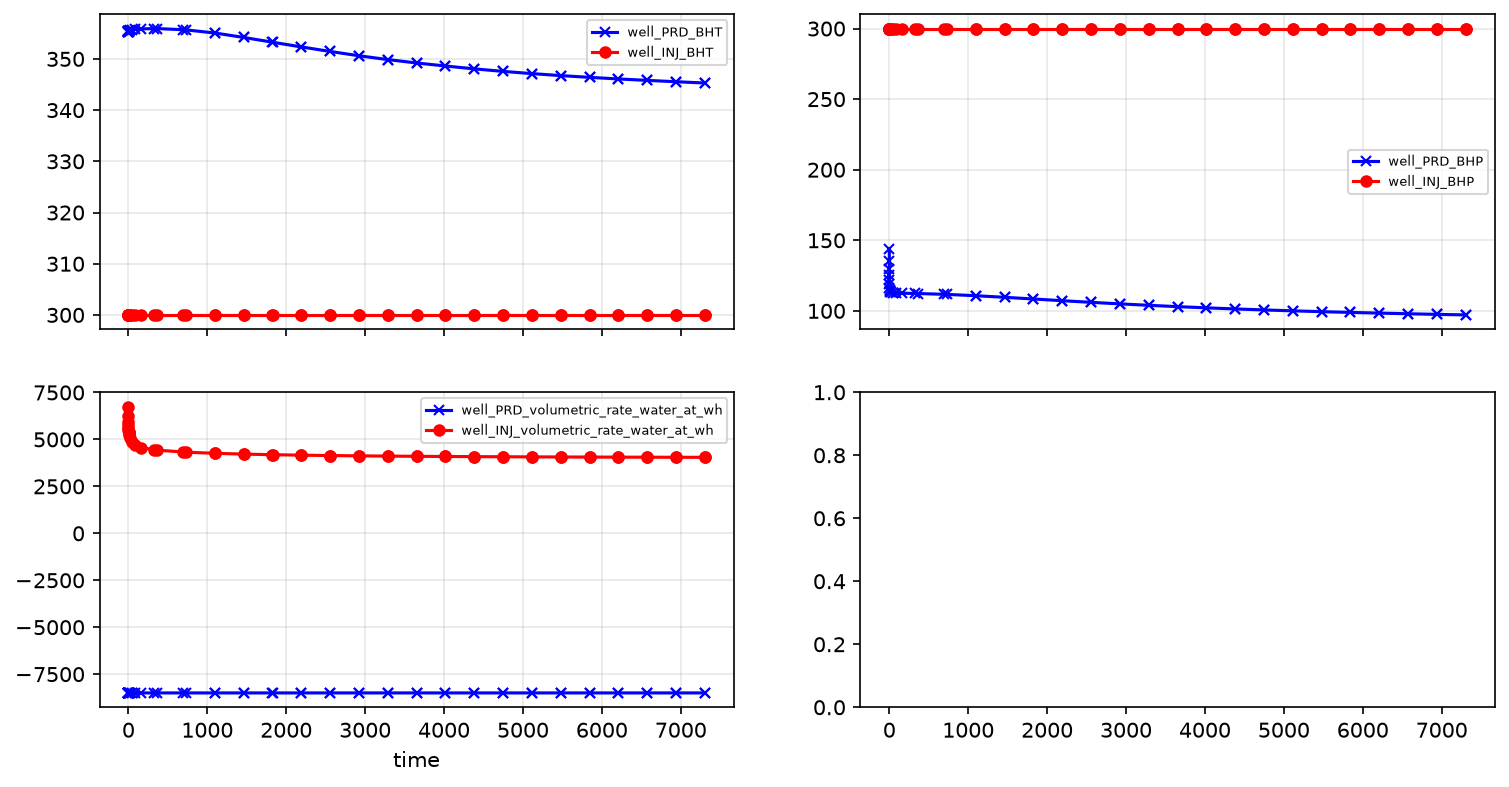

In [ ]:

# do a quick plot to get an overview of our treated data
# define a plot
fig, ax = plt.subplots(2,2, figsize=(12,6), dpi=150, sharex=True)
# get plot axes
ax_list = fig.axes

# plot a few keywords in pairs for both wells
for i, key in enumerate(['BHT', 'BHP','volumetric_rate_water']):
    tdata.plot(x='time',
              y=tdata.filter(like=key).columns.tolist(),
              ax=ax_list[i],
              linestyle='-',
              style=['x', 'o'], 
              markersize=5,
              cmap='bwr')
    ax_list[i].legend(fontsize=6)
    ax_list[i].grid(alpha=0.3)

In [ ]:

tdata['well_PRD_rho'] = [PropsSI('D', 'P', P, 'T', T, 'Water') for P, T in zip(tdata['well_PRD_BHP']*0.1 * 1e6, tdata['well_PRD_BHT'])]
tdata['well_PRD_cp']  = [PropsSI('C', 'P', P, 'T', T, 'Water') for P, T in zip(tdata['well_PRD_BHP']*0.1 * 1e6, tdata['well_PRD_BHT'])]

tdata['well_INJ_rho'] = [PropsSI('D', 'P', P, 'T', T, 'Water') for P, T in zip(tdata['well_INJ_BHP']*0.1 * 1e6, tdata['well_INJ_BHT'])]
tdata['well_INJ_cp']  = [PropsSI('C', 'P', P, 'T', T, 'Water') for P, T in zip(tdata['well_INJ_BHP']*0.1 * 1e6, tdata['well_INJ_BHT'])]

tdata['well_PRD_power'] = 1e-6 * tdata['well_PRD_volumetric_rate_water_at_wh']* m3_day_m3_sec * \
                             tdata['well_PRD_rho'] * tdata['well_PRD_cp'] * tdata['well_PRD_BHT']

tdata['well_INJ_power'] = 1e-6 * tdata['well_INJ_volumetric_rate_water_at_wh']* m3_day_m3_sec * \
                             tdata['well_INJ_rho'] * tdata['well_INJ_cp'] * tdata['well_INJ_BHT']

tdata['system_power_MW'] = abs(tdata['well_PRD_power']) - abs(tdata['well_INJ_power'])

In [ ]:
tdata.head()

,Unnamed: 0,time,well_PRD_BHP,well_PRD_BHT,well_INJ_BHP,well_INJ_BHT,well_PRD_mass_rate_water_at_wh,well_PRD_mass_rate_steam_at_wh,well_INJ_mass_rate_water_at_wh,well_INJ_mass_rate_steam_at_wh,...,well_PRD_advective_heat_rate_steam_at_wh,well_INJ_advective_heat_rate_water_at_wh,well_INJ_advective_heat_rate_steam_at_wh,well_PRD_rho,well_PRD_cp,well_INJ_rho,well_INJ_cp,well_PRD_power,well_INJ_power,system_power_MW
0,0,0.01,143.935571,355.404470,300.0,300.000115,-8.301718e+06,0,6.814009e+06,0,...,0,1.350920e+10,0,976.692251,4168.335797,1009.5708,4104.592415,-142.347322,97.116568,45.230754
1,1,0.03,135.641596,355.376507,300.0,300.000115,-8.298805e+06,0,6.316196e+06,0,...,0,1.252225e+10,0,976.349160,4169.999869,1009.5708,4104.592415,-142.342573,90.021494,52.321079
2,2,0.07,129.912396,355.358645,300.0,300.000115,-8.296808e+06,0,6.008741e+06,0,...,0,1.191270e+10,0,976.110840,4171.154907,1009.5708,4104.592415,-142.340222,85.639504,56.700719
3,3,0.15,125.480881,355.345887,300.0,300.000115,-8.295246e+06,0,5.797602e+06,0,...,0,1.149411e+10,0,975.925606,4172.051636,1009.5708,4104.592415,-142.338621,82.630248,59.708373
4,4,0.31,121.751312,355.339066,300.0,300.000115,-8.293917e+06,0,5.642064e+06,0,...,0,1.118574e+10,0,975.767108,4172.810992,1009.5708,4104.592415,-142.338721,80.413441,61.925280


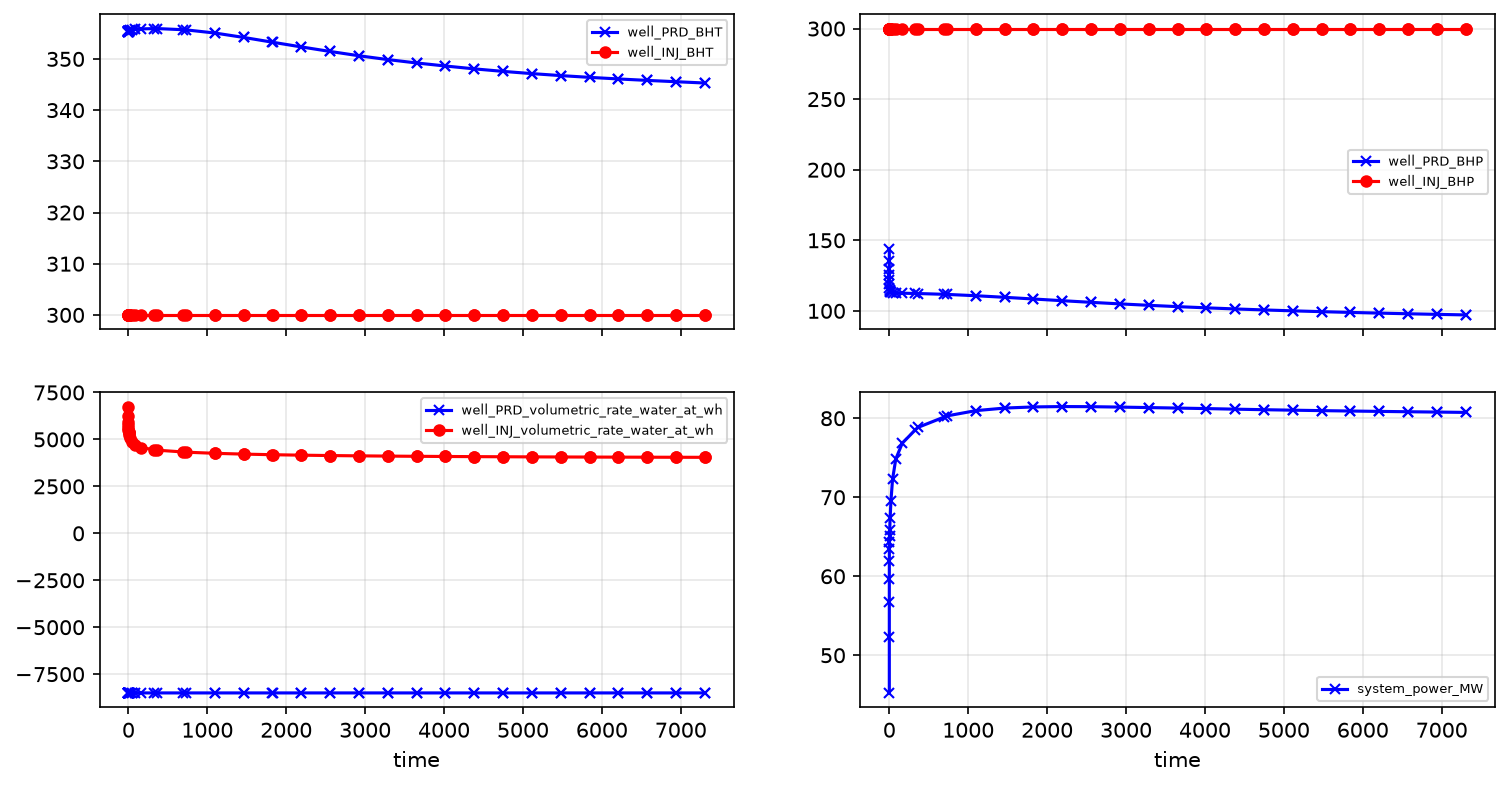

In [ ]:
fig, ax = plt.subplots(2,2, figsize=(12,6), dpi=150, sharex=True)
# get plot axes
ax_list = fig.axes

# plot a few keywords in pairs for both wells
for i, key in enumerate(['BHT', 'BHP','volumetric_rate_water', 'system_power_MW']):
    tdata.plot(x='time',
              y=tdata.filter(like=key).columns.tolist(),
              ax=ax_list[i],
              linestyle='-',
              style=['x', 'o'], 
              markersize=5,
              cmap='bwr')
    ax_list[i].legend(fontsize=6)
    ax_list[i].grid(alpha=0.3)